# CS 3630 Project 5: Differential Drive & Image Processing

## Brief
Welcome to Project 5!

We'll be covering:

- Part 1: Differential drive kinematics and odometry
- Part 2: Basic pinhole camera geometry
- Part 3: Convolutional Neural Networks
- Part 4: Inference wrapper and deployment in Webots
- Part 5: RRT\* and path smoothing
- Part 6: Dinner service - navigating the whole sushi restaurant
- Part 7: Modern visual perception with a vision-language model (website only, no code)

We'll be implementing things in a simulation environment in Webots as we go!  

**Start early, this project includes simulation components and neural network training.**

## Logistics

### Due Date: November 17th, 2026

### Submission Instructions

There are two components to this project, a coding (50%) and a reflection portion (50%), which you will submit separately on gradescope.

For the coding portion, please upload the following files directly (not inside a folder, or the autograder will not find them):

- `pinhole_camera.py`
- `networks.py`
- `low_level_controller.py`
- `rrt.py`

**For the reflection portion please fill in the powerpoint we will provide on canvas.**

## Setup

### 1. Install Webots
Install **Webots R2025a** by following the [installation guide](https://cyberbotics.com/doc/guide/installation-procedure). Open it once and run one of the sample worlds to make sure it works.

### 2. Create the Python environment
Install [Miniforge](https://github.com/conda-forge/miniforge) (it provides `conda` and `mamba`). Then, in a terminal **in this project folder**, run:
```bash
conda env create -f conda/environment.yml
conda activate cs3630_proj5
```
On macOS and Linux, `bash conda/install.sh` does the same thing with `mamba`, which is faster.

Open this notebook with the `cs3630_proj5` environment as its kernel (in VS Code: **Select Kernel** in the top right; in Jupyter: launch `jupyter notebook` from this folder with the environment activated). The notebook must run from this folder, because the imports below load `controllers/` and `tests/` from here.

### 3. Point Webots at that Python
Webots runs the robot controllers with its own Python setting, and the controllers import PyTorch, OpenCV and GTSAM, so it has to use the same environment.

1. With `cs3630_proj5` activated, run `python -c "import sys; print(sys.executable)"` and copy the path it prints.
2. In **Webots > Preferences** on macOS or **Tools > Preferences** on Windows/Linux, paste that path into **General > Python command**.
3. Restart Webots.

### 4. Open the restaurant
Choose **File > Open World** and open `worlds/sushi_restaurant.wbt`. Press **Run** (the play button) if the simulation is paused. Each controller's output appears in the Webots **console**.

- The `controller` field of the `SUSHI_BOT` node in the scene tree picks which controller the robot runs: `perception_controller` for Part 4 and `rrt_controller` for Part 6.
- **Click inside the 3D view** before pressing any keys, so that Webots sends them to the simulation (in Part 6, **1** and **2** switch between the static and dynamic restaurant).
- After you edit a controller file, press **Reset Simulation** (the rewind button) in Webots: it restarts the controllers, so they pick up your changes.

### 5. Check your setup
Run the first code cell below. If it finishes without an import error, you're ready to start Part 1.

<!-- sushi-restaurant -->
# Introduction

Welcome to **Sushi-Go-Round**, the CS 3630 revolving-sushi restaurant! Plates of sushi ride a conveyor
belt around the counter island, and the guests sit on stools all around it. Our waiter is **SUSHI-BOT**:
the same differential-drive e-puck you know, now carrying a two-tier shelf loaded with trays of drinks.

![sushi-restaurant](images/sushi_restaurant_overview.jpg)

SUSHI-BOT's job is to bring a drink to every seat. Every stool has a **seat-number card** on its backrest,
and since all the stools face the counter, the backs (and the cards) face the walkway the robot drives
through. The seat numbers are handwritten digits from the [MNIST](https://en.wikipedia.org/wiki/MNIST_database)
dataset, so SUSHI-BOT has to *read* them with a small convolutional network that you will train.

The catch: the guests are not tidy. Several stools have been **pushed out into the walkway at an angle**, so
the robot has to plan its way around them (RRT\* and path smoothing) and then actually drive the plan
with its differential-drive controller. A couple of pillars, potted bamboo, a bussing cart and a wet-floor
sign make the walkways even tighter.

![restaurant-map](images/restaurant_map.png)

The map above is drawn in the Webots world frame (x east, y north, meters). Black/red shapes are obstacles,
the orange band is how much every obstacle is grown for planning (the robot radius plus a margin), and the
blue arrows point from the place the robot has to stop to the seat card it has to read.

## Familiarizing Yourself with Webots
A good first step before starting this assignment is simply to open Webots and confirming everything works.

1. Go to Webots,
2. Click `File` and `Open World...`
3. Open `worlds/sushi_restaurant.wbt` from this project.

If everything is working you should now see the restaurant above, with the sushi plates going around the
belt. In the top left corner you should have a tile that shows what the camera of the robot (`seat_camera`) is currently seeing. If Webots isn't working, please ask a TA for help.

In [85]:
%load_ext autoreload
%autoreload 2

# sys.path.insert(0, str(Path.cwd() / "project5"))
import importlib
import sys

import controllers.perception_controller.CONSTANTS as CONSTANTS
import controllers.perception_controller.lenet_viz as lenet_viz

# Neural Network Imports
import controllers.perception_controller.networks as networks

# Pinhole Camera Imports
import controllers.perception_controller.pinhole_camera as pinhole_camera
import matplotlib.pyplot as plt
import numpy as np
import tests.test_networks as test_network
import tests.test_pinhole as test_pinhole

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Part 1: Differential Drive Kinematics

### 1.1 Inverse and Forward Kinematics

SUSHI-BOT is a differential-drive robot (DDR): it steers by spinning its two wheels at different speeds.
Section 5.2 of the textbook derives how the wheel speeds $\dot\phi_L, \dot\phi_R$ relate to the robot's
linear velocity $v$ (always along its heading) and angular velocity $\omega$, for wheels of radius $r$ that are
$L$ apart:

- **Inverse kinematics** (Equation 5.12): $\dot\phi_L = \frac{v}{r} - \frac{L}{2}\frac{\omega}{r}$ and
  $\dot\phi_R = \frac{v}{r} + \frac{L}{2}\frac{\omega}{r}$. This is what the controller uses to drive.
- **Forward kinematics** (Equation 5.13): $v = \frac{r}{2}(\dot\phi_R + \dot\phi_L)$ and
  $\omega = \frac{r}{L}(\dot\phi_R - \dot\phi_L)$. This is what odometry uses (1.2).

Turning in place is just $v = 0$ (Equation 5.11): the wheels spin at equal and opposite speeds. Every rotation
in this project (at the start of a leg, at sharp corners of a path, and when docking in front of a seat card)
calls your `_inverse_kinematics(0, ω)`.

You will implement in `low_level_controller.py`:
- `_inverse_kinematics`: wheel speeds (rad/s) from $(v, \omega)$
- `_forward_kinematics`: $(v, \omega)$ from wheel speeds (rad/s)

Use the e-puck's own `self.WHEEL_RADIUS` (2.05 cm) and `self.WHEEL_DISTANCE` (5.3 cm): the code example in
Section 5.2.2 uses a much bigger robot.

Note: `low_level_controller.py` is located at `controllers\rrt_controller\low_level_controller.py`

In [86]:
import tests.test_low_level_controller as test_low_level_controller

importlib.reload(test_low_level_controller)

print("Passed test_inverse_kinematics:", test_low_level_controller.test_inverse_kinematics())
print("Passed test_forward_kinematics:", test_low_level_controller.test_forward_kinematics())

Passed test_inverse_kinematics: True
Passed test_forward_kinematics: True


### 1.2 Odometry

The orientation $\theta$ of the robot enters its motion in exactly one place (Equation 5.14): in the world frame,
the robot moves with velocity $(v\cos\theta,\ v\sin\theta,\ \omega)$. Integrating that velocity over time gives
the robot's pose from its wheel speeds alone, without GPS: this is **odometry** (dead reckoning).

Implement `_update_odometry(pose, v, w, dt)` in `low_level_controller.py`: one Euler step of Equation 5.14,

$$x \leftarrow x + v\cos\theta\,\Delta t, \qquad y \leftarrow y + v\sin\theta\,\Delta t, \qquad \theta \leftarrow \theta + \omega\,\Delta t,$$

using the heading $\theta$ at the start of the step, and wrapping the new $\theta$ to $[-\pi, \pi]$.

In Webots, the e-puck's wheel encoders measure how far each wheel has turned. Every simulation step, the
(provided) controller turns the encoder readings into wheel speeds, calls your `_forward_kinematics` and
`_update_odometry`, and keeps this estimate next to the GPS: in Part 6 you will see how far it drifts.

The cell below tests your function and integrates a constant $(v, \omega)$ (a circle of radius $v/\omega$)
with three time steps.

Passed test_odometry: True


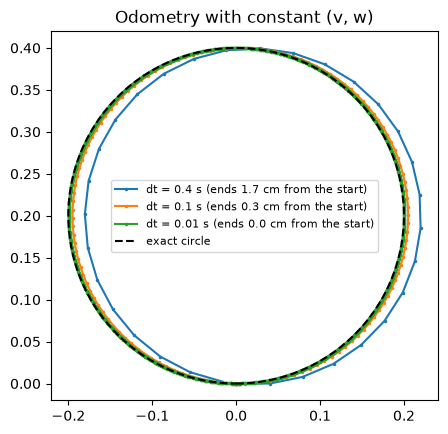

In [87]:
import gtsam

importlib.reload(test_low_level_controller)
print("Passed test_odometry:", test_low_level_controller.test_odometry())


controller = test_low_level_controller._controller()
v, w = 0.1, 0.5  # a circle of radius v / w = 0.2 m
fig, ax = plt.subplots(figsize=(5, 5))
for dt in (0.4, 0.1, 0.01):
    pose, xs, ys = gtsam.Pose2(0, 0, 0), [0.0], [0.0]
    for _ in range(int(round(2 * np.pi / w / dt))):  # one full turn
        pose = controller._update_odometry(pose, v, w, dt)
        xs.append(pose.x())
        ys.append(pose.y())
    ax.plot(
        xs,
        ys,
        ".-",
        ms=3,
        label=f"dt = {dt} s (ends {np.hypot(xs[-1], ys[-1]) * 100:.1f} cm from the start)",
    )
a = np.linspace(0, 2 * np.pi, 200)
ax.plot(v / w * np.sin(a), v / w * (1 - np.cos(a)), "k--", label="exact circle")
ax.set_aspect("equal")
ax.legend(fontsize=8)
ax.set_title("Odometry with constant (v, w)")
plt.show()

### 1.3 Heading Error and Pure Pursuit

To follow a path, the controller picks a **lookahead point** on the path about 8 cm ahead of the robot and steers
toward it with **pure pursuit**: it drives at a constant speed $v$ along an arc through the lookahead point, which
takes an angular velocity

$$\omega = \frac{2 v \sin\alpha}{L_d},$$

where $L_d$ is the distance to the lookahead point and $\alpha$ is the **heading error**: the angle the robot has to
turn through to face the point (positive to the left).

The robot only drives forward. When $|\alpha|$ is large (more than about 35°: at the start of a leg, or at a sharp
corner of the path) the provided code does not use pure pursuit: it stops and rotates in place, with
$\omega$ proportional to $\alpha$, until the point is ahead of it.

You will implement in `low_level_controller.py`:
- `_heading_error`: $\alpha$ from the robot's pose $(x, y, \theta)$ and a target point. Watch out for the
  wrap-around: a robot facing 170° with the target at -170° has to turn +20°, not -340°.
- `_calculate_pure_pursuit_velocities`: $(v, \omega)$ toward the lookahead point, with `v = self.FORWARD_SPEED`.

In [88]:
importlib.reload(test_low_level_controller)

print("Passed test_heading_error:", test_low_level_controller.test_heading_error())
print("Passed test_pure_pursuit:", test_low_level_controller.test_pure_pursuit())

Passed test_heading_error: True
Passed test_pure_pursuit: True


<!-- sushi-restaurant -->
## Part 2: Pinhole Camera Geometry

Now that SUSHI-BOT can drive and follow a path, we have a way to travel around the restaurant. Next we
need to know **where** the robot has to stop so that its camera gets a good shot of each seat-number card,
like in the image below.

![reading-a-seat-card](images/reading_seat_card.jpg)

We will make the following assumptions for simplification:

- All seat cards have their center at z = 0.125 meter height
- Our robot's camera is mounted at z = 0.125 meter height
- All seat cards are the same square size (0.06 meters) and 4 mm thick
- We know the XY location of the center of every card and the unit normal vector pointing out of the card
  face into the walkway (we give them to you in `CONSTANTS.SEAT_INFO`)
- We have a pinhole camera, and know its camera intrinsics (a focal length of 80 pixels, 32 x 32 pixels).

Note that for the stools that were pushed out at an angle, the normal vector is **not** aligned with the x
or y axis: the robot has to stand diagonally in front of those cards, at the right yaw.

**What you're going to implement:**
Given the location and normal of each card, we want to find the XY location (and yaw) the robot must drive to
in order to get a clean shot of the card. This involves camera pinhole geometry, which was
[covered in class](https://dellaert.github.io/26F-3630/Slides/L18_DDRs_2.pdf). 

<!-- sushi-restaurant -->
### 2.1 Implement Pinhole Geometry Functions in `pinhole_camera.py`

It is helpful to visualize the frustum from our robot's camera as we do this.  Go to `View`, `Optional Rendering`,
then click `Show Camera Frustums`.

To verify your implementations, you can place your robot in the positions corresponding to your calculated
translations and yaws and verify that the poses do indeed place the robot in a position to read the seat cards.

You can change the pose of your robot by dragging it around, or you can edit its pose in the scene tree by
selecting the `SUSHI_BOT` (WaiterEpuck) node and editing its translation and rotation (your rotations will only
be around the z axis!).

In [89]:
# You can test your implemenation by running the following cell.
importlib.reload(test_pinhole)
importlib.reload(pinhole_camera)


print("Passed test_find_viewing_distance:", test_pinhole.test_find_viewing_distance())
print("Passed test_find_viewing_location:", test_pinhole.test_find_viewing_location_world())

Result: 0.15, Target: 0.15
Passed test_find_viewing_distance: True
Viewing Location World: [-0.36   0.464], Yaw: -1.5707963267948966
Target Viewing Location World: [-0.36   0.464], Target Yaw: -1.5707963267948966
Seat 4 Viewing Location World: [0.148632  0.6047056], Yaw: -2.443422892782444
Passed test_find_viewing_location: True


In [90]:
from controllers.perception_controller.pinhole_camera import (
    find_viewing_distance,
    find_viewing_location_world,
)

# Now we can find the viewing locations for all 10 seat cards
card_thickness = CONSTANTS.CARD_THICKNESS_METERS
seat_info_dict = CONSTANTS.SEAT_INFO
card_size = CONSTANTS.CARD_SIZE_METERS
focal_length = CONSTANTS.FOCAL_LENGTH_PIXELS
camera_pixels = CONSTANTS.CAMERA_PIXELS

viewing_locations_world = {}
for seat_index in CONSTANTS.SEAT_INFO:
    card_translation, card_normal_vector = CONSTANTS.SEAT_INFO[seat_index]
    viewing_distance = find_viewing_distance(card_size, focal_length, camera_pixels)
    viewing_location_world, yaw = find_viewing_location_world(
        card_translation, card_normal_vector, viewing_distance, card_thickness
    )
    viewing_locations_world[seat_index] = (viewing_location_world, yaw)
    print(
        f"Viewing Location World for seat {seat_index}: {viewing_location_world}, "
        f"Yaw: {np.degrees(yaw):.1f} deg"
    )

Viewing Location World for seat 0: [-0.36   0.464], Yaw: -90.0 deg
Viewing Location World for seat 1: [ 0.2352944 -0.588632 ], Yaw: 50.0 deg
Viewing Location World for seat 2: [0.6380648 0.5358576], Yaw: -65.0 deg
Viewing Location World for seat 3: [-0.72  -0.464], Yaw: 90.0 deg
Viewing Location World for seat 4: [0.148632  0.6047056], Yaw: -140.0 deg
Viewing Location World for seat 5: [ 0.72  -0.464], Yaw: 90.0 deg
Viewing Location World for seat 6: [-0.817     0.518032], Yaw: -60.0 deg
Viewing Location World for seat 7: [-0.0336872 -0.5010896], Yaw: 80.0 deg
Viewing Location World for seat 8: [0.36  0.464], Yaw: -90.0 deg
Viewing Location World for seat 9: [-0.2228208 -0.5971792], Yaw: 135.0 deg


<!-- sushi-restaurant -->
## Part 2 Reflection Questions

1.  Place your robot in the viewing location for seat 4 (a stool that was pushed out at an angle) and visualize
    its frustum. Verify that the camera is aligned with the card and that the distance from the card indeed
    matches what we calculated from `test_find_viewing_distance`. Add a screenshot of your robot reading the card
    with the camera frustum to your report.

2.  If we ignore pixel shear, what are the 4 parameters which govern the pinhole camera model?  What does each do?

3.  Why are images on the image plane flipped in the pinhole camera model?

# Part 3: Convolutional Neural Networks


Now we have a way to move our robot around, we know our target poses, but we still don't have a way to read the seat numbers we're looking at.  Queue neural networks!  We're going to be training some simple convolutional neural networks in order to read the handwritten seat numbers :)

These are lightweight networks that you should be able to train on even a CPU.  If you're on a silicon mac, we'll be leaning on the NPU.



In [91]:
# Dependencies we'll need for neural network training

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

device = torch.device("cpu")
if torch.cuda.is_available():
    device = torch.device("cuda")  # CUDA first option
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # MPS second option

print(f"Using device: {device}")

Using device: cuda


## MNIST Dataset

We will design and train a CNN to recognize handwritten digits!

The [MNIST](https://en.wikipedia.org/wiki/MNIST_database) dataset contains 70,000 28 x 28 grayscale images of
handwritten digits 0-9 (60,000 for training and 10,000 for testing), and it is ready-to-load in PyTorch.
Every seat card in the restaurant is an MNIST digit: seat `i` shows the digit `i`.

![mnist_examples.png](images/mnist_examples.png)


## Downloading the Dataset
The code below will download the dataset and place it in the `dataset/` directory.  We will download both the train and test dataset.

In [92]:
# download dataset
train_transform = transforms.Compose(
    [
        transforms.RandomChoice(
            [
                transforms.Pad(2, fill=0, padding_mode="constant"),  # black
                transforms.Pad(2, fill=220, padding_mode="constant"),  # light gray
                transforms.Pad(2, fill=255, padding_mode="constant"),  # white
            ]
        ),
        transforms.ToTensor(),
    ]
)

train_dataset = datasets.MNIST(
    root="dataset/", train=True, transform=train_transform, download=True
)
test_dataset = datasets.MNIST(
    root="dataset/",
    train=False,
    transform=transforms.Compose([transforms.Pad(2), transforms.ToTensor()]),
    download=True,
)

## Familiarizing Yourself with the Dataset
You can use the code below to visualize a single image from the dataset.

label_idx: 7
Digit: 7
torch.Size([1, 32, 32])


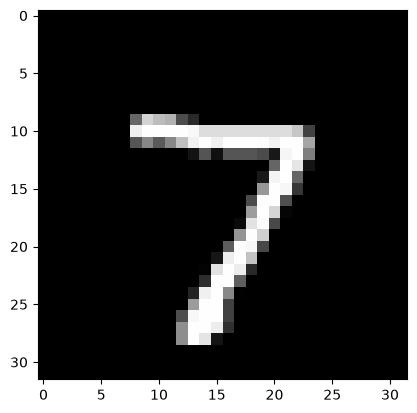

In [93]:
# Visualizing one of the digits in the dataset
img_np = test_dataset[0][0]  # An image in the test dataset
label_idx = test_dataset[0][1]
print(f"label_idx: {label_idx}")
print(f"Digit: {label_idx}")  # For MNIST, the class index is the digit itself
plt.imshow(img_np[0], cmap="Greys_r")
print(img_np.shape)

## Part 3.1: Intro to PyTorch, Simple CNN
We'll be using PyTorch to implement our Neural Network.  PyTorch beautifully abstracts away the details of backpropogation and makes it easy to implement neural networks.

Please go through the [PyTorch tutorials](https://pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html) before you move on.  


**Note 1**: Pytorch takes care of backpropagation automatically - all you have to do is define the forward pass part of the network. 

**Note 2**: In all the models used in the assignment, you will come across a "nn.Linear" layer. This is simply a Fully Connected (FC) layer, usually the final layers which map extracted features to our desired output classes.  For more details take computer vision!

We have provided an example of a simple CNN implementation in PyTorch to help you get familiar with network architecture creation.  

In [94]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        """
        Init function to define the layers
        """
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=5,  # 1 channel in (grayscale), 5 channels out, meaning we learn 5 kernels
            kernel_size=5,
            stride=3,
            padding=0,
        )  # defines the size of our convolutional filters
        self.conv2 = nn.Conv2d(in_channels=5, out_channels=48, kernel_size=5, stride=1, padding=0)
        self.linear1 = nn.Linear(48, 10)

        self.relu = nn.ReLU()  # non-linearity so we can learn non-linear decision boundaries

        self.avgpool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        """Performs forward pass with the network.

        Args:
            x: input image of shape (N,C,H,W)
               - N: size of the batch, e.g. number of images
               - C: number of channels, 1 for grayscale images
               - H: height of image
               - W: width of image
        Returns:
            model_output: the output (raw scores) of shape (N,10)

        Note:
            Gradients will be handled automatically with PyTorch.
        """
        # construct forward pass
        # x: input matrix
        x = self.conv1(x)
        x = self.relu(x)
        x = self.avgpool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = x.reshape(x.shape[0], -1)
        x = self.linear1(x)
        return x


# construct the model(e.g. neural network)
model = SimpleNet().to(device)
model

SimpleNet(
  (conv1): Conv2d(1, 5, kernel_size=(5, 5), stride=(3, 3))
  (conv2): Conv2d(5, 48, kernel_size=(5, 5), stride=(1, 1))
  (linear1): Linear(in_features=48, out_features=10, bias=True)
  (relu): ReLU()
  (avgpool): AvgPool2d(kernel_size=2, stride=2, padding=0)
)

## 3.2 Training SimpleNet

We'll define some hyperparameters for training SimpleNet:

In [95]:
# Hyperparameters
learning_rate = 0.01
num_epochs = 5
batch_size = 64

# set dataset loader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)
dataset_sizes = {"train": len(train_dataset), "test": len(test_dataset)}

# construct model
model = SimpleNet().to(device)

# loss function
criterion = nn.CrossEntropyLoss()

# define the optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [96]:
# Run training. The staff are abstracting away some of code for running testing and training.
# See the helper functions in networks.py if interested
train_losses, test_losses, simple_model_output = networks.train_and_test(
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=num_epochs,
    dataloaders=[train_loader, test_loader],
    device=device,
    dataset_sizes=dataset_sizes,
)


Epoch 1


Training loss: 0.3626125454902649
Testing loss: 0.1723686307668686

Epoch 2


Training loss: 0.1778334230184555
Testing loss: 0.12947332859039307

Epoch 3


Training loss: 0.14777342975139618
Testing loss: 0.12001625448465347

Epoch 4


Training loss: 0.13193103671073914
Testing loss: 0.11690703779459

Epoch 5


Training loss: 0.12303415685892105
Testing loss: 0.11174778640270233


## 3.3 Losses and Accuracy for SimpleNet

In this section you will plot the loss values of your training and test sets. You can use any plotting tool to do this, but matplotlib is recommended. The graph should have a general trend like this:  
<img src="https://i.imgur.com/fYg6lmt.png"> 


Head to `\controllers\perception_controller\networks.py` and implement `plot_losses`

Note:
1. The train and validation loss should decrease over time.  
2. Please include the plot title, labels for the axes and a legend to distinguish train and test losses.  
3. You will use this function to plot your losses for the neural network you actually create.

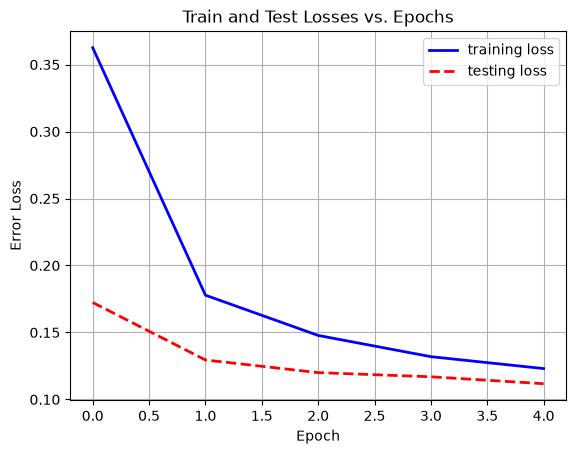

In [97]:
importlib.reload(networks)
networks.plot_losses(train_losses, test_losses)

### Accuracy

Keep in mind that loss is not the same as accuracy.  Our loss if a differentiable mathematical function that is meant to guide our network weights.  The accuracy of our network is the prediction accuracy on our test or train set.  The hope is that the loss function we choose guides our network parameters such that we increase our accuracy.

This code prints the prediction accuracy of the model on the datasets. 

In the next section, you will implement the classic CNN - LeNet, which will give you a better accuracy.

In [98]:
# Calculate accuracy
importlib.reload(networks)
accuracy = networks.accuracy

accuracy(train_loader, model, device=device)
accuracy(test_loader, model, train=False, device=device)

Model Predicted 57763 correctly out of 60000 from training dataset, Accuracy : 96.27
Model Predicted 9642 correctly out of 10000 from testing dataset, Accuracy : 96.42


If you did everything correctly you will get a testing accuracy of around 95% on SimpleNet. This is not enough for a reliable classification.  In the next section you'll implement LeNet for better results.

## 3.4 LeNet

<img src="https://i.imgur.com/PSnq4rR.gif">  

Now that you are familiar with PyTorch, you will implement LeNet which will be used to classify the handwritten digits on the seat cards for this assignment.  

LeNet (or LeCunNet) is a venerable convolutional neural network proposed by Yann LeCun et al. in 1998. 
It is one of the pioneers of CNNs that kickstarted the development of deep learning. It was originally used to recognize handwritten digits in zip codes.  

Fortunately, compared to some of the recent deep neural networks, LeNet has a relatively simple architecture and is quick to train. Training LeNet on MNIST will take under 5 minutes in an Colab GPU environment or a computer with a decent CPU/NPU. 


LeNet is composed of three convolutional layers and three fully connected layers. Here is a more detailed breakdown of LeNet layer by layer:

### LeNet Architecture
S.No | Layers | Activation Function | Output Shape (Height, Width, Channels)
--- | --- | --- | ---
1 | Input Layer | -- | 32 x 32 x 1
2 | Conv2d [6 Filters of size = 5x5, stride = 1, padding = 0 ] | ReLU | 28 x 28 x 6
3 | Average Pooling [stride = 2, padding = 0] | -- | 14 x 14 x 6
4 | Conv2d [16 Filters of size = 5x5, stride = 1, padding = 0 ] | ReLU | 10 x 10 x 16
5 | Average Pooling [stride = 2, padding = 0] | -- | 5 x 5 x 16
6 | Conv2d [120 Filters of size = 5x5, stride = 1, padding = 0 ] | ReLU | 1 x 1 x 120
7 | Flatten vector| -- | 120 
8 | Linear1 Layer | ReLU | 84 
9 | Final Linear Layer | -- | 10


Head to `networks.py` and fill in the `init` and `forward` functions for LeNet

In [99]:
importlib.reload(networks)
lenet_model = networks.LeNet()
lenet_model

LeNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (linear1): Linear(in_features=120, out_features=84, bias=True)
  (linear2): Linear(in_features=84, out_features=10, bias=True)
  (avg_pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (relu): ReLU()
)

In [100]:
importlib.reload(test_network)
# You can use this code to test your implementation
test_network.test_lenet_model_architecture()

Output shape: torch.Size([1, 10])
Layer counts - conv: 3 relu: 1 avgpool: 1 linear: 2


True

### Peek inside your LeNet (optional, not graded)

Watch a filter from **your** `conv1` slide over a digit. This uses your `LeNet` in `networks.py` (untrained weights are fine). If `forward` is unfinished, the cell will say so instead of plotting.


In [101]:
importlib.reload(networks)
importlib.reload(lenet_viz)

# One MNIST test digit (padded to 32x32 like training)
_viz_tf = transforms.Compose([transforms.Pad(2), transforms.ToTensor()])
_viz_set = datasets.MNIST(root="dataset/", train=False, transform=_viz_tf, download=True)
_viz_img, _viz_label = next((img, y) for img, y in _viz_set if int(y) == 3)

_viz_model = networks.LeNet()
lenet_viz.animate_conv_kernel(
    _viz_model,
    _viz_img,
    layer_name="conv1",
    out_channel=0,
    step=2,
    title=f"Convolution scan · digit {int(_viz_label)} (untrained weights are fine here)",
)

Great, now let's train it.

In [102]:
# Hyperparameters
# Only edit these values (for the reflection questions)!
learning_rate = 0.005
num_epochs = 10
batch_size = 128
#######################

# set dataset loader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)
dataset_sizes = {"train": len(train_dataset), "test": len(test_dataset)}

# construct model
model = networks.LeNet().to(device)

# loss function
criterion = nn.CrossEntropyLoss()

# define the optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [103]:
train_losses, test_losses, model = networks.train_and_test(
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=num_epochs,
    dataloaders=[train_loader, test_loader],
    dataset_sizes=dataset_sizes,
    device=device,
)


Epoch 1


Training loss: 0.25864484906196594
Testing loss: 0.0825687050819397

Epoch 2


Training loss: 0.07199399173259735
Testing loss: 0.05619683116674423

Epoch 3


Training loss: 0.05126302316784859
Testing loss: 0.046975281089544296

Epoch 4


Training loss: 0.04367339611053467
Testing loss: 0.06545990705490112

Epoch 5


Training loss: 0.035275477916002274
Testing loss: 0.053457312285900116

Epoch 6


Training loss: 0.03224838152527809
Testing loss: 0.04934392124414444

Epoch 7


Training loss: 0.02799735963344574
Testing loss: 0.03878213092684746

Epoch 8


Training loss: 0.025517456233501434
Testing loss: 0.04762620851397514

Epoch 9


Training loss: 0.022564085200428963
Testing loss: 0.04678986966609955

Epoch 10


Training loss: 0.021757474169135094
Testing loss: 0.04348914697766304


Let's take a look at our accuracy.  You will need > 98% accuracy on the test set.  If you don't get there with the parameters we gave you, feel free to tweak the batchsize or learning rate!

In [104]:
accuracy = networks.accuracy(test_loader, model, train=False, device=device)

Model Predicted 9883 correctly out of 10000 from testing dataset, Accuracy : 98.83


### Save and Load Model

Use the code below to save the model weights or load the pre-saved model that contains the trained model weights.  

You can use this to avoid training the network every time you re-load the Colab environment. 
Make sure you download the `checkpoint.pt` file locally as it will be deleted when the environment is reloaded. 

We will also need this checkpoint when we load the model into the Webots environment.

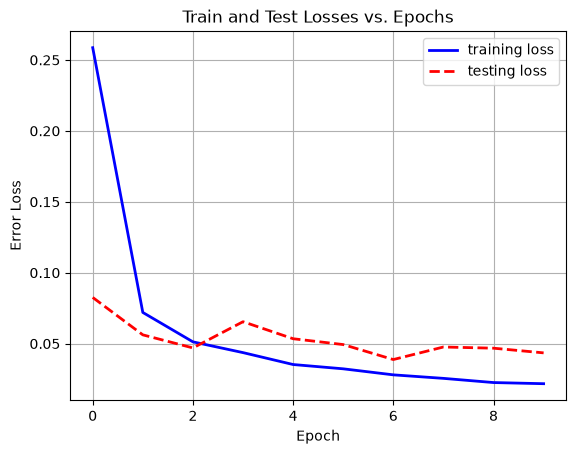

In [105]:
# Keep in mind that if you run this again with a different model you will overwrite Final_LeNet.pt
model_path_to_save_to = CONSTANTS.TRAINED_MODEL_PATH
torch.save({"model_state_dict": model.state_dict()}, model_path_to_save_to)
networks.plot_losses(train_losses, test_losses)

### 3D forward pass (optional, not graded)

After training, this animates how **your** LeNet turns the image into a digit prediction (feature-map planes in depth, then softmax). Sidebar labels stay fixed while the camera drifts slowly.


In [106]:
importlib.reload(networks)
importlib.reload(lenet_viz)

_viz_tf = transforms.Compose([transforms.Pad(2), transforms.ToTensor()])
_viz_set = datasets.MNIST(root="dataset/", train=False, transform=_viz_tf, download=True)
_viz_img, _viz_label = next((img, y) for img, y in _viz_set if int(y) == 3)

# Prefer the model you just trained; fall back to a fresh LeNet if needed
try:
    _viz_model = model
except NameError:
    _viz_model = networks.LeNet()

lenet_viz.animate_forward_pass(
    _viz_model,
    _viz_img,
    title=f"3D forward pass · digit {int(_viz_label)}",
)

## Part 3 Reflection Questions

1. What is the shape of the feature map after an image from the MNIST dataset is passed through the first convolution layer of SimpleNet? (self.conv1)? [Answer as (No. of Channels, Height, Width)]
2. What does `out_channels` represent in a convolutional layer?
3. How many total learnable parameter are there in SimpleNet vs. LeNet?  There are useful pytorch function for this, use the internet!  Why does this allow LeNet to perform better?

4.  Attach a visualization of your loss plot **for LeNet** from your `plot_losses` function

# Part 4: Inference Wrapper

Now we have a nice neural network that we can use to read seat-number cards.  In practice, networks are usually wrapped in an inference class that handles the logistics or "plumbing" around the network like loading the network, preprocessing data, and processing outputs.

In this section, you'll be implementing the ImageClassifier class which wraps our trained LeNet and:
- Loads the network from a path
- Does image preprocessing
- Runs inference
- Processes the network output

Implement the `ImageClassifier` class in `Networks.py`

In [107]:
# You can test your implementation with the code below
importlib.reload(networks)
importlib.reload(test_network)

print(test_network.test_image_classifier_class_to_character())
print(test_network.test_image_classifier_preprocess_image())
print(test_network.test_image_classifier_single_inference())

Character: 9 for class index: 9
True
Preprocessed image shape: torch.Size([1, 1, 32, 32])
True
Prediction successful.  Predicted class index: 8
True


/home/jfonseca32/github/Classes/courses/CS-3630_Introduction_to_Perception_and_Robotics/Homeworks/P5/controllers/perception_controller/networks.py:398: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this

<!-- sushi-restaurant -->
### Webots Deployment

Let's test this on some images from Webots!  To do this we're going to switch over to a hack controller that
teleports our robot around to the correct viewing locations.

To switch the controller in use, open `worlds/sushi_restaurant.wbt`, select the `SUSHI_BOT` (WaiterEpuck) node in
the scene tree (it is at the very bottom of the file) and change its `controller` field to
`perception_controller`. You'll have to switch this back to `rrt_controller` for Part 6.

This controller will teleport the robot to each of the viewing locations you computed in Part 2, run inference,
and save an image per location to `controllers/perception_controller/inference_test_frames`. The outputs from
inference are printed to the Webots console.  Pretty cool.

<!-- sushi-restaurant -->
### Observations

There are 10 seats in the restaurant, one for each digit 0-9: seat `i` has the MNIST digit `i` on its card.

Your model will most likely do worse on these frames than the ~99% it scored on the test set. Why might this be?
Take a look at the captured images used for inference, specifically the ones that failed. Compare them with the
training images: think about the brightness of the strokes, the black frame around each card, the lighting of the
restaurant, and the stools that are seen at an angle.

<!-- sushi-restaurant -->
## Part 4 Reflection Questions
1.  If your model performed worse in the Webots environment than on the test set, speculate as to why?  Provide one
    or two images that the network made incorrect predictions on.
2.  What changes could we make in order to train a model that generalizes better to our Webots deployment?

<!-- sushi-restaurant -->
# Part 5: RRT* and Path Smoothing

Section 5.5.5 of the textbook builds a **Rapidly-exploring Random Tree (RRT)** from the start: sample a random
point, find the nearest node of the tree, and take a step from it toward the sample ("turn toward the target, then
drive"). Like the textbook, we plan for the **position** $(x, y)$ of the robot only, with straight edges. That is
exact for SUSHI-BOT, not an approximation: the e-puck is round, so whether it collides does not depend on its
heading, and it can turn in place, so any heading can be reached at any free point.

RRT finds *a* path quickly and stops, but that path is usually far from the shortest one: it zig-zags around the
restaurant. **RRT\*** (Karaman & Frazzoli, 2011) adds two steps to every iteration and keeps sampling after the
goal is found:

1. **Choose parent.** Once a new point `x_new` is sampled (and pulled toward the tree by `steer`), we look
   at *all* the tree nodes within a radius `r` of it (`near_nodes`) and attach `x_new` to the one that gives the
   lowest **cost-to-come**: `cost(x_near) + length(segment x_near -> x_new)`, among the segments that are
   collision free.
2. **Rewire.** For every near node `x_near`, if going *through* `x_new` is cheaper than its current
   cost-to-come, `cost(x_new) + length(segment x_new -> x_near) < cost(x_near)` (and that segment is collision
   free), then `x_new` becomes the parent of `x_near`. The cost of every descendant of `x_near` drops by the same
   amount.

The neighborhood radius shrinks like `gamma * sqrt(log(n) / n)` as the tree grows, which is what makes RRT\*
*asymptotically optimal*: with more and more samples, the path converges to the shortest one.

### What you will implement, in `controllers/rrt_controller/rrt.py`

- `RRTStar.choose_parent(new_key, near_keys)`
- `RRTStar.rewire(new_key, near_keys)`

Everything else is provided: `steer`, `near_nodes`, `edge_cost`, `edge_path`, `path_is_free`, `add_node`,
`change_parent` (which also propagates the new cost to the descendants) and the main loop `run`. Read through
`RRTStar` before you start.

### The planner's world

The planner does not work in meters: `rrt_controller.py` converts the Webots coordinates to *planner units*
(50 units per meter, with the south-west corner of the dining room at the origin). The obstacles come from
`restaurant_map.py` and are **inflated** by the robot radius plus a safety margin (`environment.py`): the robot
center only has to stay out of the inflated obstacles, so we can plan for a point instead of a disc. This is the
configuration space of Section 5.5.1.

In [108]:
import tests.test_rrt_star as test_rrt_star

importlib.reload(test_rrt_star)

print("Passed test_choose_parent:", test_rrt_star.test_choose_parent())
print("Passed test_rewire:", test_rrt_star.test_rewire())
print("Passed test_rrt_star_improves:", test_rrt_star.test_rrt_star_improves())

Passed test_choose_parent: True
Passed test_rewire: True
first solution 124.0, final 102.1 (planner units)
Passed test_rrt_star_improves: True


<!-- sushi-restaurant -->
### 5.1 RRT vs. RRT* in the restaurant

The cell below picks a random leg of the dinner service (from the drink station or a seat to another seat) and
plans it with both planners, then plots the trees, the paths, and how the length of the best RRT\* path evolves
with the number of iterations. The leg and its seed are printed; set `LEG_SEED` to replay a leg.

Planning seat 8 -> seat 4 (LEG_SEED = 976786)


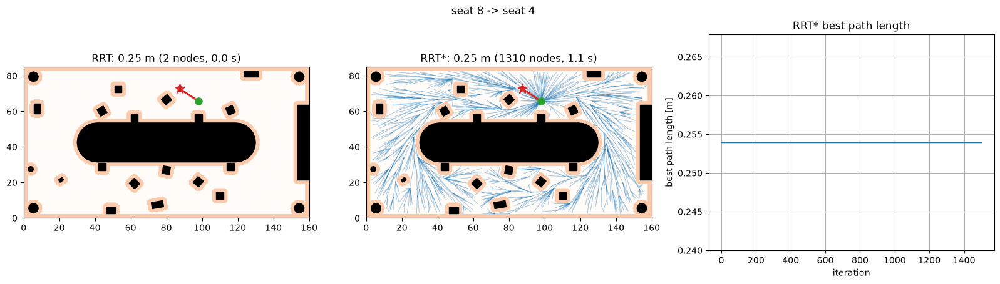

In [109]:
import random

sys.path.insert(0, "controllers/rrt_controller")
import matplotlib.pyplot as plt
import restaurant_map
import rrt as rrt_module
from environment import StaticEnvironment

importlib.reload(rrt_module)

SCALE = 50.0
ORIGIN = np.array([restaurant_map.ROOM_X[0], restaurant_map.ROOM_Y[0]])


def to_planner(x, y):
    return ((x - ORIGIN[0]) * SCALE, (y - ORIGIN[1]) * SCALE)


env = StaticEnvironment(
    dimensions=(
        (restaurant_map.ROOM_X[1] - restaurant_map.ROOM_X[0]) * SCALE,
        (restaurant_map.ROOM_Y[1] - restaurant_map.ROOM_Y[0]) * SCALE,
    ),
    obstacle_vertices_list=[
        [to_planner(x, y) for x, y in poly] for _, poly in restaurant_map.OBSTACLES
    ],
    inflation=(restaurant_map.ROBOT_RADIUS + restaurant_map.PLANNER_MARGIN) * SCALE,
)

# Pick a random leg: from the drink station or a seat to a different seat.
# Set LEG_SEED to the seed printed below to replay that exact leg.
LEG_SEED = None
leg_seed = LEG_SEED if LEG_SEED is not None else random.randrange(10**6)
leg_rng = random.Random(leg_seed)
stops = {
    "drink station": restaurant_map.HOME_POSE,
    **{f"seat {i}": pose for i, pose in restaurant_map.SEAT_VIEWING_POSES.items()},
}
start_name = leg_rng.choice(list(stops))
goal_name = leg_rng.choice([n for n in stops if n.startswith("seat") and n != start_name])
print(f"Planning {start_name} -> {goal_name} (LEG_SEED = {leg_seed})")

hx, hy, ht = stops[start_name]
gx, gy, gt = stops[goal_name]
start, goal = (*to_planner(hx, hy), ht), (*to_planner(gx, gy), gt)

np.random.seed(0)
t0 = time.time()
plain = rrt_module.RRT(env)
plain.set_start(start)
plain.run(goal=goal, nb_iteration=1000, goal_rate=0.75)
t_rrt = time.time() - t0

np.random.seed(0)
t0 = time.time()
star = rrt_module.RRTStar(env)
star.set_start(start)
star.run(goal=goal, nb_iteration=1500, goal_rate=0.1)
t_star = time.time() - t0

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
env.plot(axes[0])
plain.plot(axes[0])
fig.suptitle(f"{start_name} -> {goal_name}")
axes[0].set_title(
    f"RRT: {plain.path_cost() / SCALE:.2f} m ({len(plain.nodes)} nodes, {t_rrt:.1f} s)"
)
env.plot(axes[1])
star.plot(axes[1])
axes[1].set_title(
    f"RRT*: {star.path_cost() / SCALE:.2f} m ({len(star.nodes)} nodes, {t_star:.1f} s)"
)
axes[2].plot(np.array(star.cost_history) / SCALE)
axes[2].set_xlabel("iteration")
axes[2].set_ylabel("best path length [m]")
axes[2].set_title("RRT* best path length")
axes[2].grid(True)
plt.show()

<!-- sushi-restaurant -->
### 5.2 Smoothing the path

The RRT\* path is made of straight segments, and SUSHI-BOT only drives forward. At every corner it would have to
stop and rotate in place, and pure pursuit, which aims 8 cm ahead, would cut the corners toward the stools.
`smooth_path` (provided, in `rrt.py`) fixes this:

- a corner that turns by less than 60° is replaced by a circular arc tangent to both segments (a **fillet**),
  of radius 8 cm, made smaller if the arc would hit an obstacle;
- a sharper corner is kept: the robot drives to it, stops and rotates in place.

**What you will implement:** `fillet_corner(p_prev, p, p_next, radius, point_separation)` in `rrt.py`.
With $u_1$ and $u_2$ the unit directions of the two segments and $\varphi$ the angle the path turns by at `p`:

- the arc touches the segments at $T_1 = p - t\,u_1$ and $T_2 = p + t\,u_2$, with $t = r \tan(\varphi/2)$
  (if $t$ is longer than half of either segment, use that half length and the matching radius instead);
- the center of the arc is at distance $r$ from $T_1$, on the side the path turns toward;
- sample the arc from $T_1$ to $T_2$ with points at most `point_separation` apart.

Each arc is driven with a constant $(v, \omega)$: a circle of radius $r = v / \omega$, like in 1.2.

Passed test_fillet_corner: True
Passed test_smooth_path: True


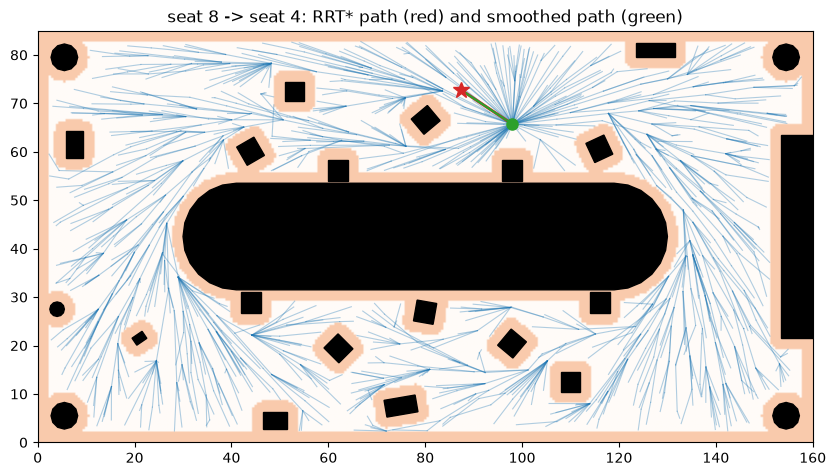

In [110]:
import tests.test_smoothing as test_smoothing

importlib.reload(test_smoothing)
importlib.reload(rrt_module)

print("Passed test_fillet_corner:", test_smoothing.test_fillet_corner())
print("Passed test_smooth_path:", test_smoothing.test_smooth_path())

# Smooth the RRT* path from 5.1
smoothed = rrt_module.smooth_path(star.extract_waypoints(), env)
fig, ax = plt.subplots(figsize=(10, 5.5))
env.plot(ax)
star.plot(ax, smoothed=smoothed)
ax.set_title(f"{start_name} -> {goal_name}: RRT* path (red) and smoothed path (green)")
plt.show()

<!-- sushi-restaurant -->
## Part 5 Reflection Questions
1. Add the RRT vs. RRT\* figure from 5.1 to your report. How much shorter is the RRT\* path? How long did each
   planner take?
2. Explain in your own words why rewiring can only *decrease* the best path length (look at your plot of the
   best path length). Why does `change_parent` need to update the cost of all the descendants of a rewired node?
3. SUSHI-BOT's configuration is $(x, y, \theta)$, but we planned for $(x, y)$ only. Which two properties of
   the e-puck make that valid? Which one would break for a rectangular robot, and which for a car-like robot that
   cannot turn in place?
4. The neighborhood radius shrinks as the tree grows. What happens to the running time and to the path quality if
   it is (a) very large, (b) very small?
5. Add the smoothed path from 5.2 to your report. Why do we round only the gentle corners and rotate in place at
   the sharp ones? What would the fillet of a corner that turns by 170° look like, and why would the robot have
   trouble following it?

<!-- sushi-restaurant -->
## Part 6: Dinner service: serving every seat

Now that we have tools to plan around the pushed-out stools, to drive the plans, and to read the seat cards, it's
time for the dinner rush! Starting from the drink station on the east side of the restaurant, SUSHI-BOT has to
visit all ten seats. The order is shuffled on every run (the seat order and its seed are printed to the
Webots console; set `SEAT_ORDER_SEED` in `rrt_controller.py` to replay a run, or `SHUFFLE_SEAT_ORDER = False`
to go 0, 1, ..., 9). At every seat it stops at the viewing pose you
computed in Part 2, reads the card with your classifier and serves the drink. When every seat has been served, it
plans its way back to the drink station.

Switch the `controller` field of `SUSHI_BOT` back to `rrt_controller` and run the simulation. There is no code to
write for this part: `run_mission` in `rrt_controller.py` is provided. For each seat it plans the leg with your
RRT\* and smoothing code, drives it with your controller and reads the card with your classifier before moving on
to the next seat.

While the mission runs, `rrt_controller.py` saves a picture of the RRT\* tree of every leg to
`controllers/rrt_controller/planner_plots/` and the camera frame of every seat to
`controllers/rrt_controller/inference_test_frames/`. After every leg, the console also prints the **odometry
drift**: how far the pose integrated from the wheel encoders (your 1.1 and 1.2 code) is from the GPS and compass,
over that leg and over the whole mission. Set `DRIVE_ON_ODOMETRY = True` at the top of `rrt_controller.py` to make
the robot drive on odometry alone.

To score points for this part you need to
- Submit the frames captured at each seat, with your predictions
- Submit a screenshot (or a short screen recording) of SUSHI-BOT driving around a pushed-out stool

Submit this as part of the reflection questions in the ppt.

### The dynamic dinner rush

Once the mission runs, click the 3D view and press **2** to switch to the dynamic simulation (press **1** to
go back to static, or set `SIMULATION_MODE = "dynamic"` at the top of `rrt_controller.py` to start in it).
Customers walk in, sit down and push their stools around. SUSHI-BOT reads where its target stool is at the start
of each leg, and while driving it uses the e-puck's infra-red proximity sensors to notice anything that is not on
its map, stops, and replans the rest of the leg with your RRT\*. There is nothing to implement here: it is your
kinematics, controller, RRT\* and smoothing code doing the work.

<!-- sushi-restaurant -->
## Part 6 Reflection Questions
1. Paste all the frames captured at the seats onto the powerpoint slide with the predicted digits. The cards on
   the pushed-out stools were seen at the yaw you computed in Part 2: do those frames look different from the others?
   What issues might imperfect alignment (a robot that stops 1-2 cm or a few degrees away from the goal) cause for
   inference?
2. Watch one leg of the mission. Where did SUSHI-BOT rotate in place, and where did it drive arcs? Why does the
   controller make the robot reach a sharp corner before turning, instead of letting pure pursuit cut it?
3. Report the odometry drift printed after a few legs and for the whole mission. Did it grow faster on straight
   segments, on arcs or during rotations in place, and why? (Optional: run a few legs with
   `DRIVE_ON_ODOMETRY = True` and describe what happens.)
4. Even though the planner inflates every obstacle by the robot radius, the robot can still brush a stool. Using the
   planner and the controller code (`environment.py`, `rrt.py`, `low_level_controller.py`), give two reasons why the
   path the robot actually drives differs from the planned one. Which parameter would you change first, and what is
   the trade-off?
5. Run the mission in dynamic mode (press 2). Add a screenshot or short recording of SUSHI-BOT stopping and  replanning around something that wasn’t on its map. How many replans happened over the whole mission? Did any leg fail or take much longer than in static mode, and why?


<!-- sushi-restaurant -->
# Part 7: Modern Visual Perception with a Vision-Language Model

The LeNet you trained in Part 3 is a small classic CNN that takes a 32x32 grayscale image and outputs one of 10
digit classes. It has to be trained from scratch for that single task, and it can never recognize anything that
isn't a digit. Robot perception today looks very different. Robots increasingly use large **vision-language
models (VLMs)**: one pretrained model that does many perception tasks and finds *any* object you can describe in
words ("open-vocabulary" perception) instead of a fixed list of classes.

In this part you will try one of these models on images of your choice. **There is nothing to install,
train or code**: everything happens on a website.

### The model: WeVisOne-VL-2B

[WeVisOne-VL-2B](https://huggingface.co/tencent/WeVisOne-VL-2B) is an open-source model from WeChat Vision (Tencent), built on the Qwen3-VL
vision-language model. It has about 2 billion parameters, and the same model does all of these tasks:

| Task (in the website's **Task** menu) | What it does |
| --- | --- |
| Grounding | Draws a box around the object your query describes, e.g. "the cup closest to the laptop" |
| Dense Detection | Finds every instance of the object category in your query, e.g. "chair" |
| Counting (boxes / points) | Counts the objects in your query, marking each one with a box or a point |
| Pointing | Puts a point on the object your query describes |
| OCR (all text / text grounding) | Reads all the text in the image, or finds where a given piece of text is |
| Grounded Caption / VQA | Answers a question about the image in sentences ("visual question answering"), e.g. "Describe this image in detail." |
| Segmentation | Produces a pixel mask of the object your query describes |
| Matting | Produces a soft (alpha) cutout of the object, e.g. for hair or fur edges |

Instead of having a separate "box head", the model *writes* its answers as text. Boxes and points are written as
special coordinate tokens `<0>` to `<1000>`, which are coordinates normalized to the image size (0 is the left/top
edge, 1000 is the right/bottom edge). Masks come from a small extra decoder on top of the language model.

### Using the website

1. Open the demo: **https://huggingface.co/spaces/hugging-apps/wevisone-vl-2b**
2. Upload an image under **Input image**.
3. Pick a **Task**, type a **Query** (the object, expression or question), and press **Run**.
4. The **Result** panel shows the boxes, points or masks drawn on your image, and **Raw model output** shows the
   exact text the model generated.

Notes:
- The demo runs on a free, shared GPU, so you may have to wait in a queue, and Hugging Face limits how much GPU time
  each visitor gets per day. If you see a quota error, try again later or sign in with a free Hugging Face account.
  **Don't leave this to the night before the deadline.**
- Your images are sent to a third-party server. Use photos you took yourself, and don't upload anything private
  or pictures of people who haven't agreed to it.

<!-- sushi-restaurant -->
## Part 7 Reflection Questions

For every question, include a screenshot of the website showing your input image, the task and query you used, the **Result** and the **Raw model output**.

1. **Describe a scene.** Upload a photo you took yourself of a real scene with several objects in it (your desk, a
   kitchen, a meal, a street, ...). Run **Grounded Caption / VQA** with the query `Describe this image in detail.`
   What did the model get right? Did it miss anything, or describe something that isn't actually there (a
   "hallucination")?
2. **Find objects.** On the same image or a new one:
   - Run **Dense Detection** or **Counting (boxes)** on an object category that appears several times.
   - Run **Grounding** with a query that needs context to answer, such as "the mug to the left of the keyboard".
   - Run **Grounding** with a query for something that is **not** in the image. What does the model return? Why
     does it matter for a robot that a detector can say "it isn't there"?
3. **Reading the raw output.** Pick one box from the **Raw model output** of question 2. Write down the image's width
   and height in pixels, and convert the box's four `<0>`-`<1000>` coordinates into pixel coordinates. Your LeNet
   outputs a vector of 10 scores. In one or two sentences, explain how this model can output a box when all it
   generates is text.
4. **Back to the restaurant.** Upload one of the seat cards from `images/seat_cards/` (or a photo of a digit you
   wrote by hand) and ask the model what number is on the card with **Grounded Caption / VQA** or **OCR (all text)**.
   Did it read the card correctly?
   - Compare the number of parameters in LeNet (Part 3, Reflection Question 3) with WeVisOne-VL's ~2 billion.
   - Give one reason SUSHI-BOT should still use your LeNet to read the seat cards, and one task in the sushi
     restaurant where a model like WeVisOne-VL would help (for example, what you would ask it and which task you
     would use).